<a href="https://colab.research.google.com/github/nurfahdilla293/praktikum_evaluasi_model.ipynb/blob/main/praktikum_evaluasi_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Ke-7: Laporan Evaluasi Model Lengkap

Pada praktikum ini saya membandingkan dua model klasifikasi, yaitu **Logistic Regression** dan **Decision Tree**, menggunakan dataset `load_breast_cancer` dari scikit-learn. Tujuannya adalah melihat model mana yang paling baik dan paling aman dalam mendeteksi kanker payudara.

**Catatan:** di dataset ini label aslinya `0 = malignant` (ganas) dan `1 = benign` (jinak). Karena dalam kasus ini yang paling berbahaya adalah kanker ganas yang tidak terdeteksi (*false negative*), label saya balik menjadi **1 = malignant** supaya kelas ganas menjadi kelas positif.

## Langkah 1 - Muat dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, precision_score,
                             recall_score, f1_score, accuracy_score, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score,
                             classification_report)

data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = 1 - data.target   # dibalik: 1 = malignant (positif), 0 = benign

print("Ukuran data:", X.shape)
print("Distribusi kelas (0=benign, 1=malignant):")
print(pd.Series(y).value_counts())

Ukuran data: (569, 30)
Distribusi kelas (0=benign, 1=malignant):
0    357
1    212
Name: count, dtype: int64


## Langkah 2 - Split stratified 70:30

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporsi malignant train:", y_train.mean().round(3), "| test:", y_test.mean().round(3))

Train: (398, 30) | Test: (171, 30)
Proporsi malignant train: 0.372 | test: 0.374


## Langkah 3 - Latih Logistic Regression dan Decision Tree

In [3]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=42),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    print(name, "selesai dilatih")

Logistic Regression selesai dilatih
Decision Tree selesai dilatih


## Langkah 4 - Confusion matrix, precision, recall, F1

 Logistic Regression 
               precision    recall  f1-score   support

      Benign       0.96      0.99      0.98       107
   Malignant       0.98      0.94      0.96        64

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171

 Decision Tree 
               precision    recall  f1-score   support

      Benign       0.88      0.98      0.93       107
   Malignant       0.96      0.78      0.86        64

    accuracy                           0.91       171
   macro avg       0.92      0.88      0.90       171
weighted avg       0.91      0.91      0.90       171



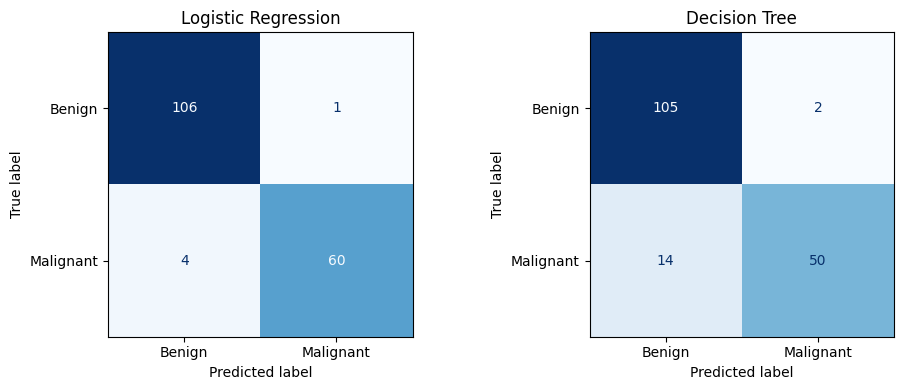

,TN,FP,FN,TP,Accuracy,Precision,Recall,F1
Model,,,,,,,,
Logistic Regression,106,1,4,60,0.9708,0.9836,0.9375,0.9600
Decision Tree,105,2,14,50,0.9064,0.9615,0.7812,0.8621


In [4]:
rows = []
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (name, m) in zip(axes, models.items()):
    y_pred = m.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["Benign", "Malignant"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)

    tn, fp, fn, tp = cm.ravel()
    rows.append({
        "Model": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
    })
    print("=" * 50, "\n", name, "\n", classification_report(y_test, y_pred, target_names=["Benign", "Malignant"]))

plt.tight_layout(); plt.show()
df_metrik = pd.DataFrame(rows).set_index("Model").round(4)
df_metrik

## Langkah 5a - ROC-AUC dan PR Curve

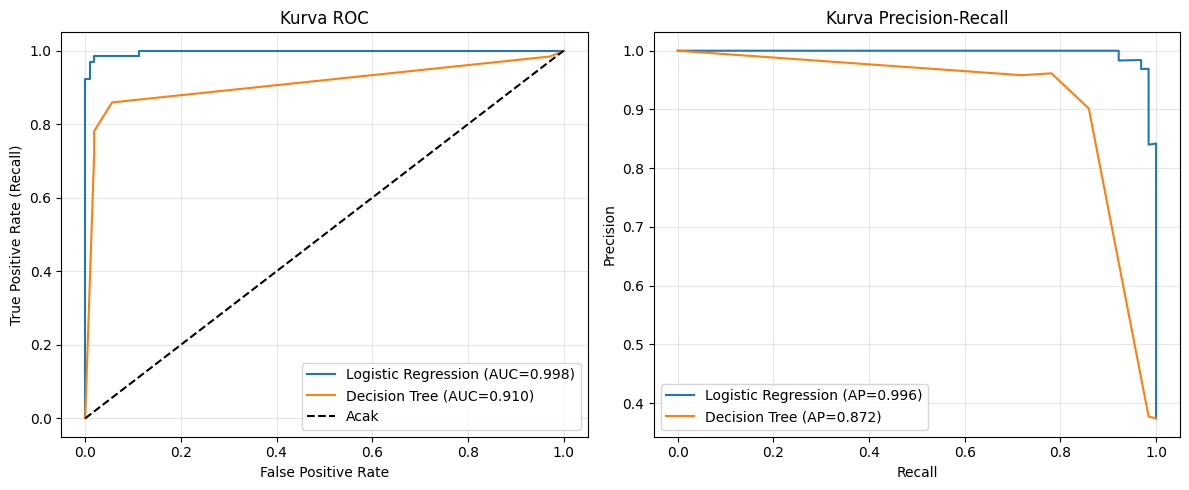

,ROC-AUC,Average Precision (PR-AUC)
Model,,
Logistic Regression,0.9975,0.9963
Decision Tree,0.9095,0.8723


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
auc_rows = []

for name, m in models.items():
    proba = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    prec, rec, _ = precision_recall_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    ap = average_precision_score(y_test, proba)
    auc_rows.append({"Model": name, "ROC-AUC": auc, "Average Precision (PR-AUC)": ap})

    axes[0].plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
    axes[1].plot(rec, prec, label=f"{name} (AP={ap:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", label="Acak")
axes[0].set(xlabel="False Positive Rate", ylabel="True Positive Rate (Recall)", title="Kurva ROC")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Kurva Precision-Recall")
for a in axes: a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

df_auc = pd.DataFrame(auc_rows).set_index("Model").round(4)
df_auc

## Langkah 5b - Mean dan SD dari 5-fold Cross Validation

In [6]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"recall": "recall", "precision": "precision", "f1": "f1",
           "roc_auc": "roc_auc", "pr_auc": "average_precision"}

cv_rows = []
for name, m in models.items():
    res = cross_validate(m, X, y, cv=skf, scoring=scoring)
    row = {"Model": name}
    for k in scoring:
        s = res[f"test_{k}"]
        row[f"{k} mean"] = s.mean()
        row[f"{k} SD"] = s.std()
    cv_rows.append(row)

df_cv = pd.DataFrame(cv_rows).set_index("Model").round(4)
df_cv

,recall mean,recall SD,precision mean,precision SD,f1 mean,f1 SD,roc_auc mean,roc_auc SD,pr_auc mean,pr_auc SD
Model,,,,,,,,,,
Logistic Regression,0.9436,0.0525,0.9863,0.0182,0.9633,0.0240,0.9953,0.0053,0.9943,0.0057
Decision Tree,0.8728,0.0718,0.9177,0.0419,0.8928,0.0429,0.9152,0.0367,0.8788,0.0541


## Rangkuman perbandingan (ROC, PR, mean CV, SD)

In [7]:
ringkasan = pd.DataFrame({
    "Recall (test)": df_metrik["Recall"],
    "FN (test)": df_metrik["FN"],
    "ROC-AUC (test)": df_auc["ROC-AUC"],
    "PR-AUC (test)": df_auc["Average Precision (PR-AUC)"],
    "Recall CV mean": df_cv["recall mean"],
    "Recall CV SD": df_cv["recall SD"],
    "ROC-AUC CV mean": df_cv["roc_auc mean"],
    "ROC-AUC CV SD": df_cv["roc_auc SD"],
})
ringkasan

,Recall (test),FN (test),ROC-AUC (test),PR-AUC (test),Recall CV mean,Recall CV SD,ROC-AUC CV mean,ROC-AUC CV SD
Model,,,,,,,,
Logistic Regression,0.9375,4,0.9975,0.9963,0.9436,0.0525,0.9953,0.0053
Decision Tree,0.7812,14,0.9095,0.8723,0.8728,0.0718,0.9152,0.0367
